In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dataset/house_prices.csv")

print(df.head())

   Area  Bedrooms  Age  Price
0   800         2   20     35
1  1000         2   15     45
2  1200         3   12     55
3  1400         3   10     65
4  1600         3    8     75


In [2]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape:
(10, 4)

Column Names:
Index(['Area', 'Bedrooms', 'Age', 'Price'], dtype='str')

Missing Values:
Area        0
Bedrooms    0
Age         0
Price       0
dtype: int64

Duplicate Rows:
0


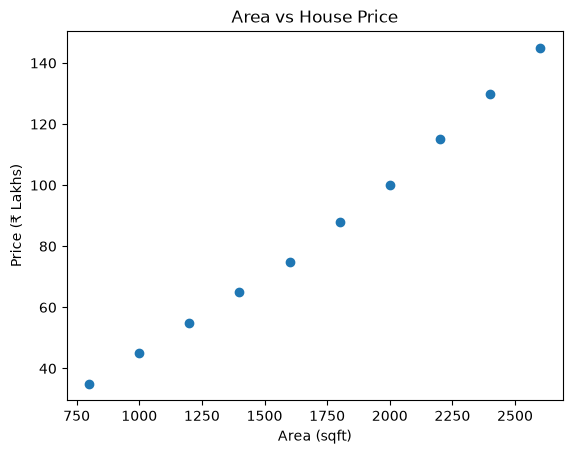

In [3]:
plt.scatter(df["Area"], df["Price"])

plt.xlabel("Area (sqft)")
plt.ylabel("Price (₹ Lakhs)")
plt.title("Area vs House Price")

plt.show()

In [4]:
correlation = df.corr()

print(correlation)

              Area  Bedrooms       Age     Price
Area      1.000000  0.968330 -0.973592  0.995892
Bedrooms  0.968330  1.000000 -0.943371  0.965822
Age      -0.973592 -0.943371  1.000000 -0.952346
Price     0.995892  0.965822 -0.952346  1.000000


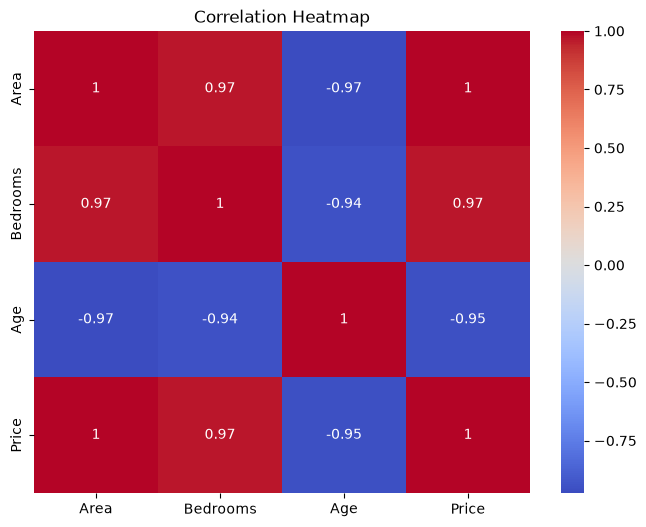

In [5]:
plt.figure(figsize=(8, 6))

sns.heatmap(df.corr(), annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

In [6]:
X = df[["Area", "Bedrooms", "Age"]]
y = df["Price"]

print("Features (X):")
print(X)

print("\nTarget (y):")
print(y)

Features (X):
   Area  Bedrooms  Age
0   800         2   20
1  1000         2   15
2  1200         3   12
3  1400         3   10
4  1600         3    8
5  1800         4    6
6  2000         4    5
7  2200         4    3
8  2400         5    2
9  2600         5    1

Target (y):
0     35
1     45
2     55
3     65
4     75
5     88
6    100
7    115
8    130
9    145
Name: Price, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8, 3)
Testing data: (2, 3)


In [8]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Actual Prices:")
print(y_test.values)

print("\nPredicted Prices:")
print(y_pred)

Actual Prices:
[130  45]

Predicted Prices:
[130.29396985  40.73241206]


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 2.2807788944723697
MSE: 9.14936254766292
RMSE: 3.024791322994517
R² Score: 0.9949346089701521


In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X_simple = df[["Area"]]
y_simple = df["Price"]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y_simple, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)

y_pred_s = simple_model.predict(X_test_s)

print("Actual Prices:")
print(y_test_s.values)

print("\nPredicted Prices:")
print(y_pred_s)

print("\nMAE:", mean_absolute_error(y_test_s, y_pred_s))
print("MSE:", mean_squared_error(y_test_s, y_pred_s))
print("RMSE:", np.sqrt(mean_squared_error(y_test_s, y_pred_s)))
print("R² Score:", r2_score(y_test_s, y_pred_s))

Actual Prices:
[130  45]

Predicted Prices:
[127.23275862  42.26724138]

MAE: 2.749999999999993
MSE: 7.562797265160484
RMSE: 2.7500540476798787
R² Score: 0.99581298421306


In [11]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X_poly = df[["Area"]]
y_poly = df["Price"]

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_poly, y_poly, test_size=0.2, random_state=42
)

poly_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

poly_model.fit(X_train_p, y_train_p)

y_pred_p = poly_model.predict(X_test_p)

print("Actual Prices:")
print(y_test_p.values)

print("\nPredicted Prices:")
print(y_pred_p)

mae_p = mean_absolute_error(y_test_p, y_pred_p)
mse_p = mean_squared_error(y_test_p, y_pred_p)
rmse_p = np.sqrt(mse_p)
r2_p = r2_score(y_test_p, y_pred_p)

print("\nMAE:", mae_p)
print("MSE:", mse_p)
print("RMSE:", rmse_p)
print("R² Score:", r2_p)

Actual Prices:
[130  45]

Predicted Prices:
[129.32292256  44.35740531]

MAE: 0.659836065574531
MSE: 0.43568089859365955
RMSE: 0.6600612839681325
R² Score: 0.9997587925820934


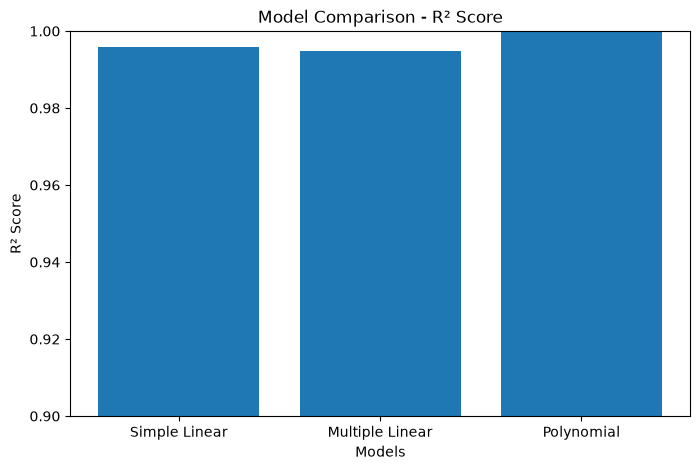

In [12]:
models = ["Simple Linear", "Multiple Linear", "Polynomial"]

r2_scores = [
    r2_score(y_test_s, y_pred_s),
    r2_score(y_test, y_pred),
    r2_p
]

plt.figure(figsize=(8, 5))
plt.bar(models, r2_scores)

plt.xlabel("Models")
plt.ylabel("R² Score")
plt.title("Model Comparison - R² Score")

plt.ylim(0.9, 1.0)
plt.show()

In [13]:
new_house = pd.DataFrame({
    "Area": [1800],
    "Bedrooms": [3],
    "Age": [5]
})

predicted_price = model.predict(new_house)

print("House Details:")
print("Area:", 1800, "sqft")
print("Bedrooms:", 3)
print("Age:", 5, "years")

print("\nPredicted House Price: ₹", round(predicted_price[0], 2), "Lakhs")

House Details:
Area: 1800 sqft
Bedrooms: 3
Age: 5 years

Predicted House Price: ₹ 84.57 Lakhs


In [1]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Area"], df["Price"])

plt.xlabel("Area (sqft)")
plt.ylabel("Price (₹ Lakhs)")
plt.title("Area vs House Price")

plt.savefig("../graphs/area_vs_price.png")
plt.show()

NameError: name 'plt' is not defined

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dataset/house_prices.csv")

print(df.head())

   Area  Bedrooms  Age  Price
0   800         2   20     35
1  1000         2   15     45
2  1200         3   12     55
3  1400         3   10     65
4  1600         3    8     75


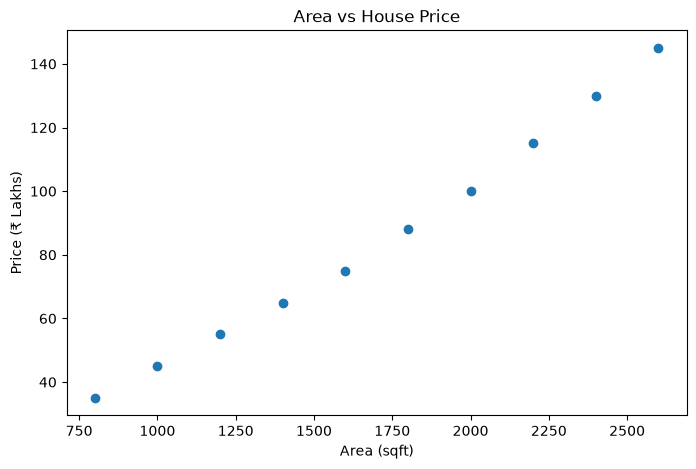

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Area"], df["Price"])

plt.xlabel("Area (sqft)")
plt.ylabel("Price (₹ Lakhs)")
plt.title("Area vs House Price")

plt.savefig("../graphs/area_vs_price.png")
plt.show()

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dataset/house_prices.csv")

print(df.head())


   Area  Bedrooms  Age  Price
0   800         2   20     35
1  1000         2   15     45
2  1200         3   12     55
3  1400         3   10     65
4  1600         3    8     75


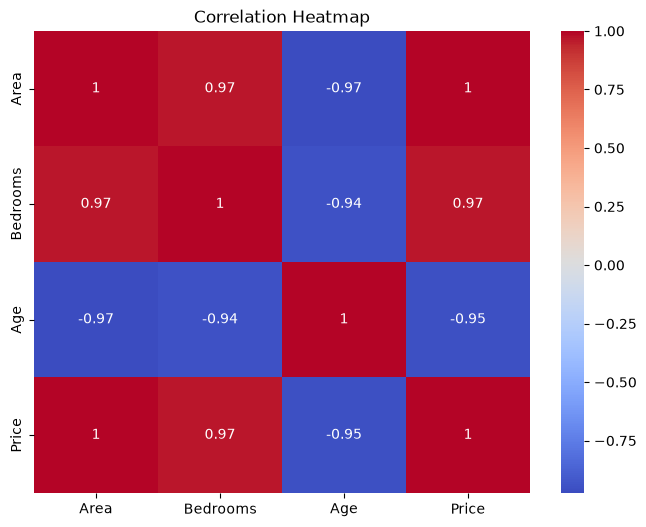

In [3]:
plt.figure(figsize=(8, 6))

sns.heatmap(df.corr(), annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.savefig("../graphs/correlation_heatmap.png")

plt.show()

In [4]:
models = ["Simple Linear", "Multiple Linear", "Polynomial"]

r2_scores = [
    r2_score(y_test_s, y_pred_s),
    r2_score(y_test, y_pred),
    r2_p
]

plt.figure(figsize=(8, 5))

plt.bar(models, r2_scores)

plt.xlabel("Models")
plt.ylabel("R² Score")
plt.title("Model Comparison - R² Score")

plt.ylim(0.9, 1.0)

plt.savefig("../graphs/model_comparison.png")

plt.show()

NameError: name 'r2_score' is not defined

In [5]:
from sklearn.metrics import r2_score

In [6]:
models = ["Simple Linear", "Multiple Linear", "Polynomial"]

r2_scores = [
    r2_score(y_test_s, y_pred_s),
    r2_score(y_test, y_pred),
    r2_p
]

plt.figure(figsize=(8, 5))

plt.bar(models, r2_scores)

plt.xlabel("Models")
plt.ylabel("R² Score")
plt.title("Model Comparison - R² Score")

plt.ylim(0.9, 1.0)

plt.savefig("../graphs/model_comparison.png")

plt.show()

NameError: name 'y_test_s' is not defined

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

X_simple = df[["Area"]]
y_simple = df["Price"]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple,
    y_simple,
    test_size=0.2,
    random_state=42
)

simple_model = LinearRegression()

simple_model.fit(X_train_s, y_train_s)

y_pred_s = simple_model.predict(X_test_s)

print("Simple Linear Regression R² Score:")
print(r2_score(y_test_s, y_pred_s))


Simple Linear Regression R² Score:
0.99581298421306


In [8]:
from sklearn.linear_model import LinearRegression

X = df[["Area", "Bedrooms", "Age"]]
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

y_pred = multiple_model.predict(X_test)

print("Multiple Linear Regression R² Score:")
print(r2_score(y_test, y_pred))

Multiple Linear Regression R² Score:
0.9949346089701521


In [9]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

X_poly = df[["Area"]]
y_poly = df["Price"]

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_poly,
    y_poly,
    test_size=0.2,
    random_state=42
)

poly_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

poly_model.fit(X_train_p, y_train_p)

y_pred_p = poly_model.predict(X_test_p)

r2_p = r2_score(y_test_p, y_pred_p)

print("Polynomial Regression R² Score:")
print(r2_p)

Polynomial Regression R² Score:
0.9997587925820934


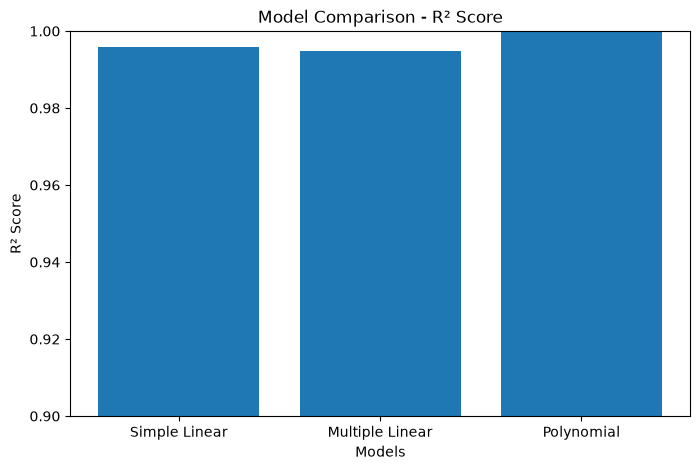

In [10]:
models = ["Simple Linear", "Multiple Linear", "Polynomial"]

r2_scores = [
    r2_score(y_test_s, y_pred_s),
    r2_score(y_test, y_pred),
    r2_p
]

plt.figure(figsize=(8, 5))

plt.bar(models, r2_scores)

plt.xlabel("Models")
plt.ylabel("R² Score")
plt.title("Model Comparison - R² Score")

plt.ylim(0.9, 1.0)

plt.savefig("../graphs/model_comparison.png")

plt.show()